### Visualización, preprocesamiento y modelo base

Antes de usar modelos preentrenados, necesitamos un **punto de referencia** (*baseline*): un modelo clásico de NLP con el que comparar. Así podremos medir cuánto aporta realmente el transfer learning.

Este notebook está estructurado como sigue:

- **BLOQUE A**: carga de los datos.
- **BLOQUE B**: visualización.
- **BLOQUE C**: preprocesamiento del texto.
- **BLOQUE D**: partición en entrenamiento y validación (80/20).
- **BLOQUE E**: vectorización del texto con TF-IDF.
- **BLOQUE F**: entrenamiento del modelo base (regresión logística).
- **BLOQUE G**: evaluación sobre las noticias nuevas (2020-21).
- **BLOQUE H**: exportación.

In [1]:
# Preparación del entorno: funciona tanto en Google Colab como en local
import os, sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not os.path.exists("seminario-manadine-transfer-learning"):
    !git clone -q https://github.com/Vins16/seminario-manadine-transfer-learning.git
    %pip install -q -r seminario-manadine-transfer-learning/requirements.txt

if EN_COLAB:
    RAIZ = "seminario-manadine-transfer-learning"
else:
    RAIZ = "." if os.path.exists("data") else ".."
sys.path.insert(0, RAIZ)
DATA = f"{RAIZ}/data"
MODELS = f"{RAIZ}/models"

In [2]:
import re
import unicodedata

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from stop_words import get_stop_words
from wordcloud import WordCloud

sns.set_theme(style="whitegrid")

### BLOQUE A: carga de los datos

In [3]:
df = pd.read_csv(f"{DATA}/noticias_2018.csv")
df_nuevas = pd.read_csv(f"{DATA}/noticias_2020_21.csv")
df.head()

,Id,Topic,texto,longitud,target
0,1,Educación,"RAE INCLUIRÁ LA PALABRA ""LADY"" EN EL DICCIONAR...",2605,1
1,2,Educación,"La palabra ""haiga"", aceptada por la RAE La Rea...",1063,1
2,3,Educación,YORDI ROSADO ESCRIBIRÁ Y DISEÑARÁ LOS NUEVOS L...,2469,1
3,4,Educación,UNAM capacitará a maestros para aprobar prueba...,1086,0
4,5,Educación,pretenden aprobar libros escolares con conteni...,5496,1


### BLOQUE B: visualización

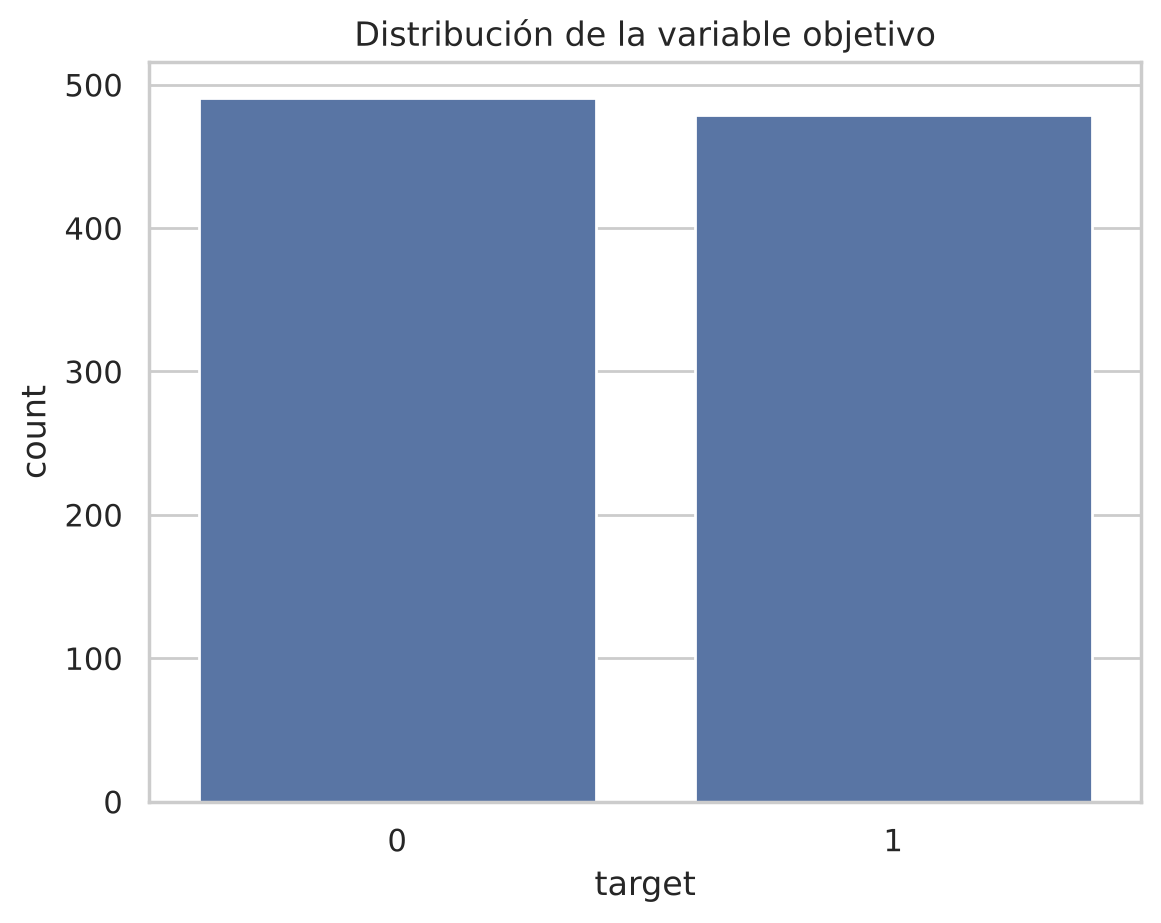

In [4]:
# ¿Cuántas noticias hay de cada clase? (1 = falsa, 0 = verdadera)
sns.countplot(data=df, x="target")
plt.title("Distribución de la variable objetivo")
plt.show()

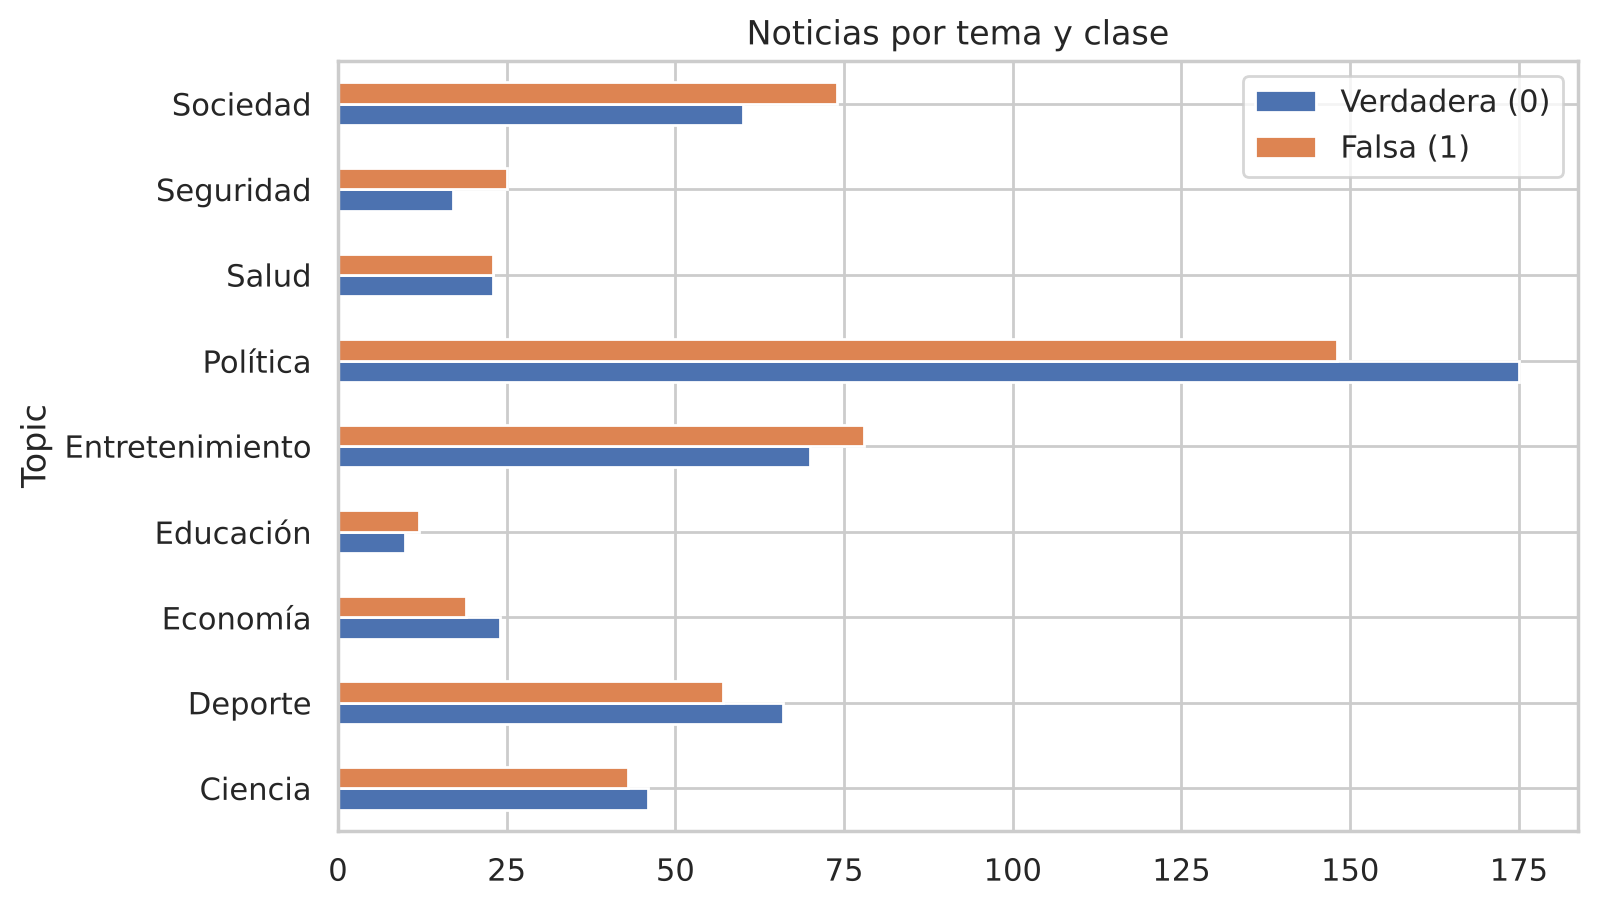

In [5]:
# Número de noticias falsas y verdaderas por tema
pd.crosstab(df["Topic"], df["target"]).plot(kind="barh", figsize=(8, 5))
plt.title("Noticias por tema y clase")
plt.legend(["Verdadera (0)", "Falsa (1)"])
plt.show()

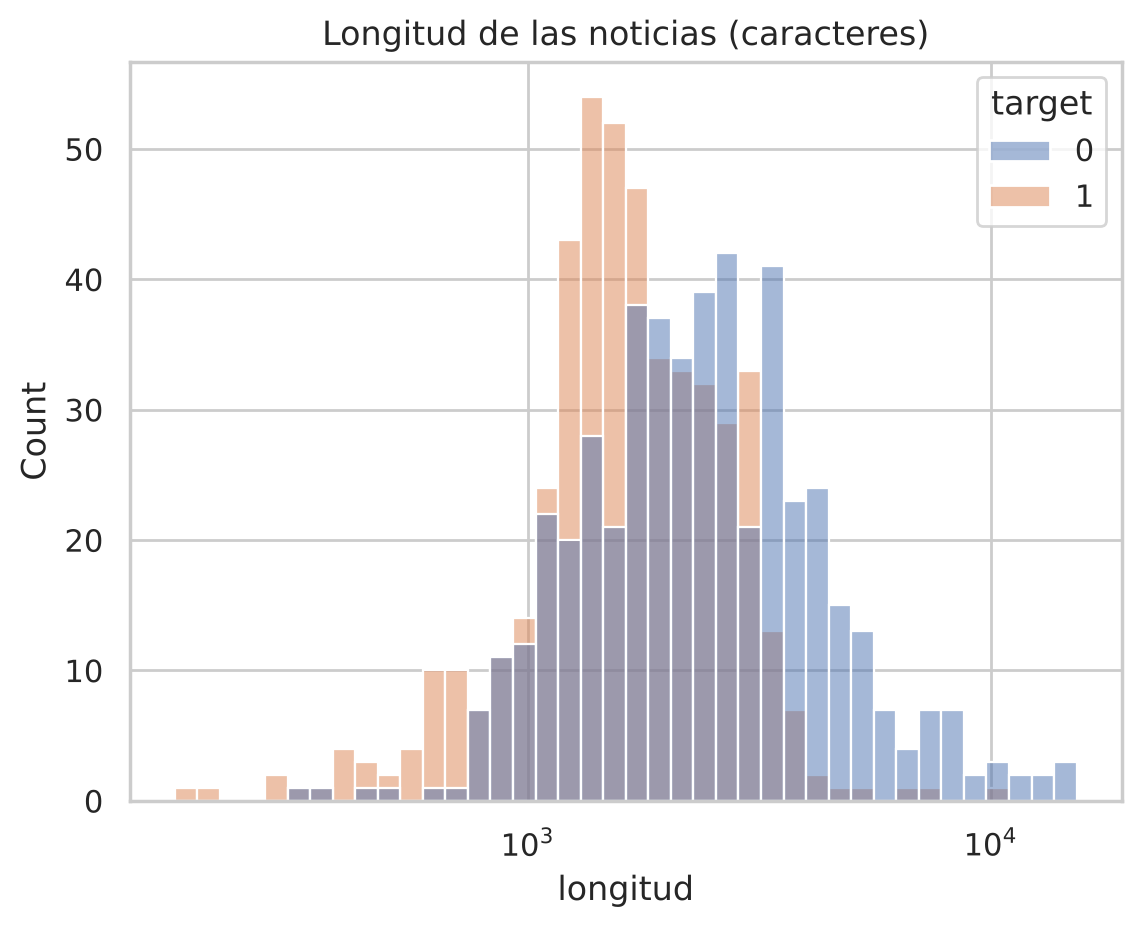

In [6]:
# Distribución de la longitud de las noticias según su clase (eje X en escala logarítmica)
sns.histplot(data=df, x="longitud", hue="target", bins=40, log_scale=True)
plt.title("Longitud de las noticias (caracteres)")
plt.show()

¿Recuerdas la función `proporcion_mayusculas` del notebook 1? Comprobemos si los bulos "gritan" más.

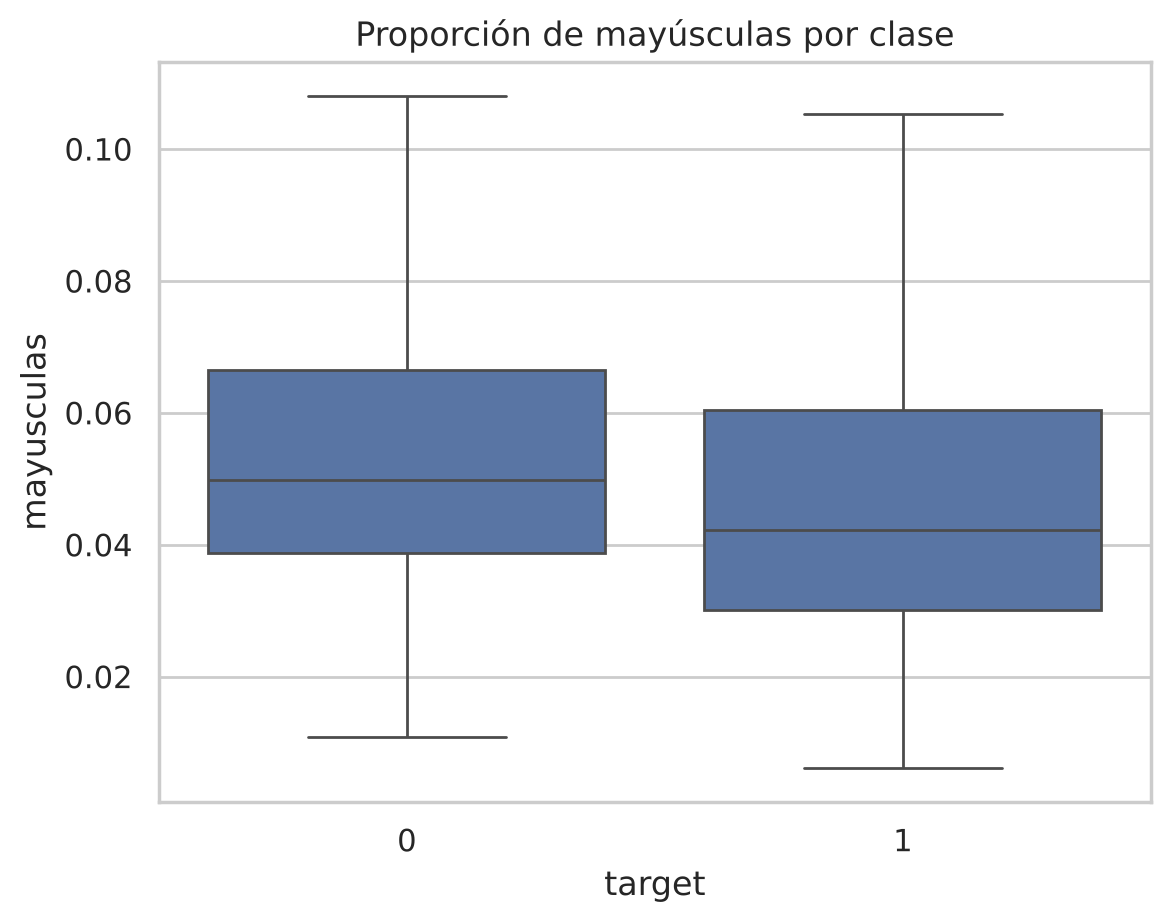

In [7]:
def proporcion_mayusculas(texto):
    letras = [c for c in texto if c.isalpha()]
    if len(letras) == 0:
        return 0
    return sum(c.isupper() for c in letras) / len(letras)


df["mayusculas"] = df["texto"].apply(proporcion_mayusculas)

sns.boxplot(data=df, x="target", y="mayusculas", showfliers=False)
plt.title("Proporción de mayúsculas por clase")
plt.show()

### BLOQUE C: preprocesamiento del texto

Los modelos clásicos tratan cada palabra como un símbolo independiente: para ellos, *"Gobierno"*, *"gobierno"* y *"gobiernó"* son tres palabras distintas. Por eso normalizamos el texto:

1. Pasamos todo a minúsculas.
2. Quitamos tildes.
3. Eliminamos números y signos de puntuación.
4. Eliminamos las **palabras vacías** (*stopwords*): "el", "de", "que"... que aparecen en todas las noticias y no aportan información.

In [8]:
def quitar_tildes(texto):
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c))


STOPWORDS_ES = {quitar_tildes(p) for p in get_stop_words("spanish")}
print(len(STOPWORDS_ES), "palabras vacías. Algunas:", sorted(STOPWORDS_ES)[:15])

627 palabras vacías. Algunas: ['a', 'acerca', 'actualmente', 'adelante', 'ademas', 'adonde', 'aestarian', 'afirmo', 'agrego', 'ahi', 'ahora', 'al', 'algo', 'algun', 'alguna']


In [9]:
def preprocesar(texto):
    texto = quitar_tildes(texto.lower())
    texto = re.sub(r"[^a-z\s]", " ", texto)    # nos quedamos solo con letras y espacios
    tokens = [t for t in texto.split() if t not in STOPWORDS_ES and len(t) > 2]
    return " ".join(tokens)


ejemplo = df["texto"].iloc[0][:250]
print("ANTES: ", ejemplo)
print("\nDESPUÉS:", preprocesar(ejemplo))

ANTES:  RAE INCLUIRÁ LA PALABRA "LADY" EN EL DICCIONARIO DEL IDIOMA ESPAÑOL COMO DEFINICIÓN DE "MUJER PROBLEMÁTICA" España.- El presidente de la Real Academia Española (RAE), Darío Villanueva, informó en conferencia de prensa que a partir del próximo mes se 

DESPUÉS: rae incluira palabra lady diccionario idioma espanol definicion mujer problematica espana presidente real academia espanola rae dario villanueva conferencia prensa mes


> Estas funciones también están en el fichero `utils.py`, para poder reutilizarlas en el notebook 4.

In [10]:
df["texto_prep"] = df["texto"].apply(preprocesar)
df_nuevas["texto_prep"] = df_nuevas["texto"].apply(preprocesar)

¿Qué palabras son más frecuentes en cada clase? Una **nube de palabras** lo muestra de un vistazo: cuanto más grande, más frecuente.

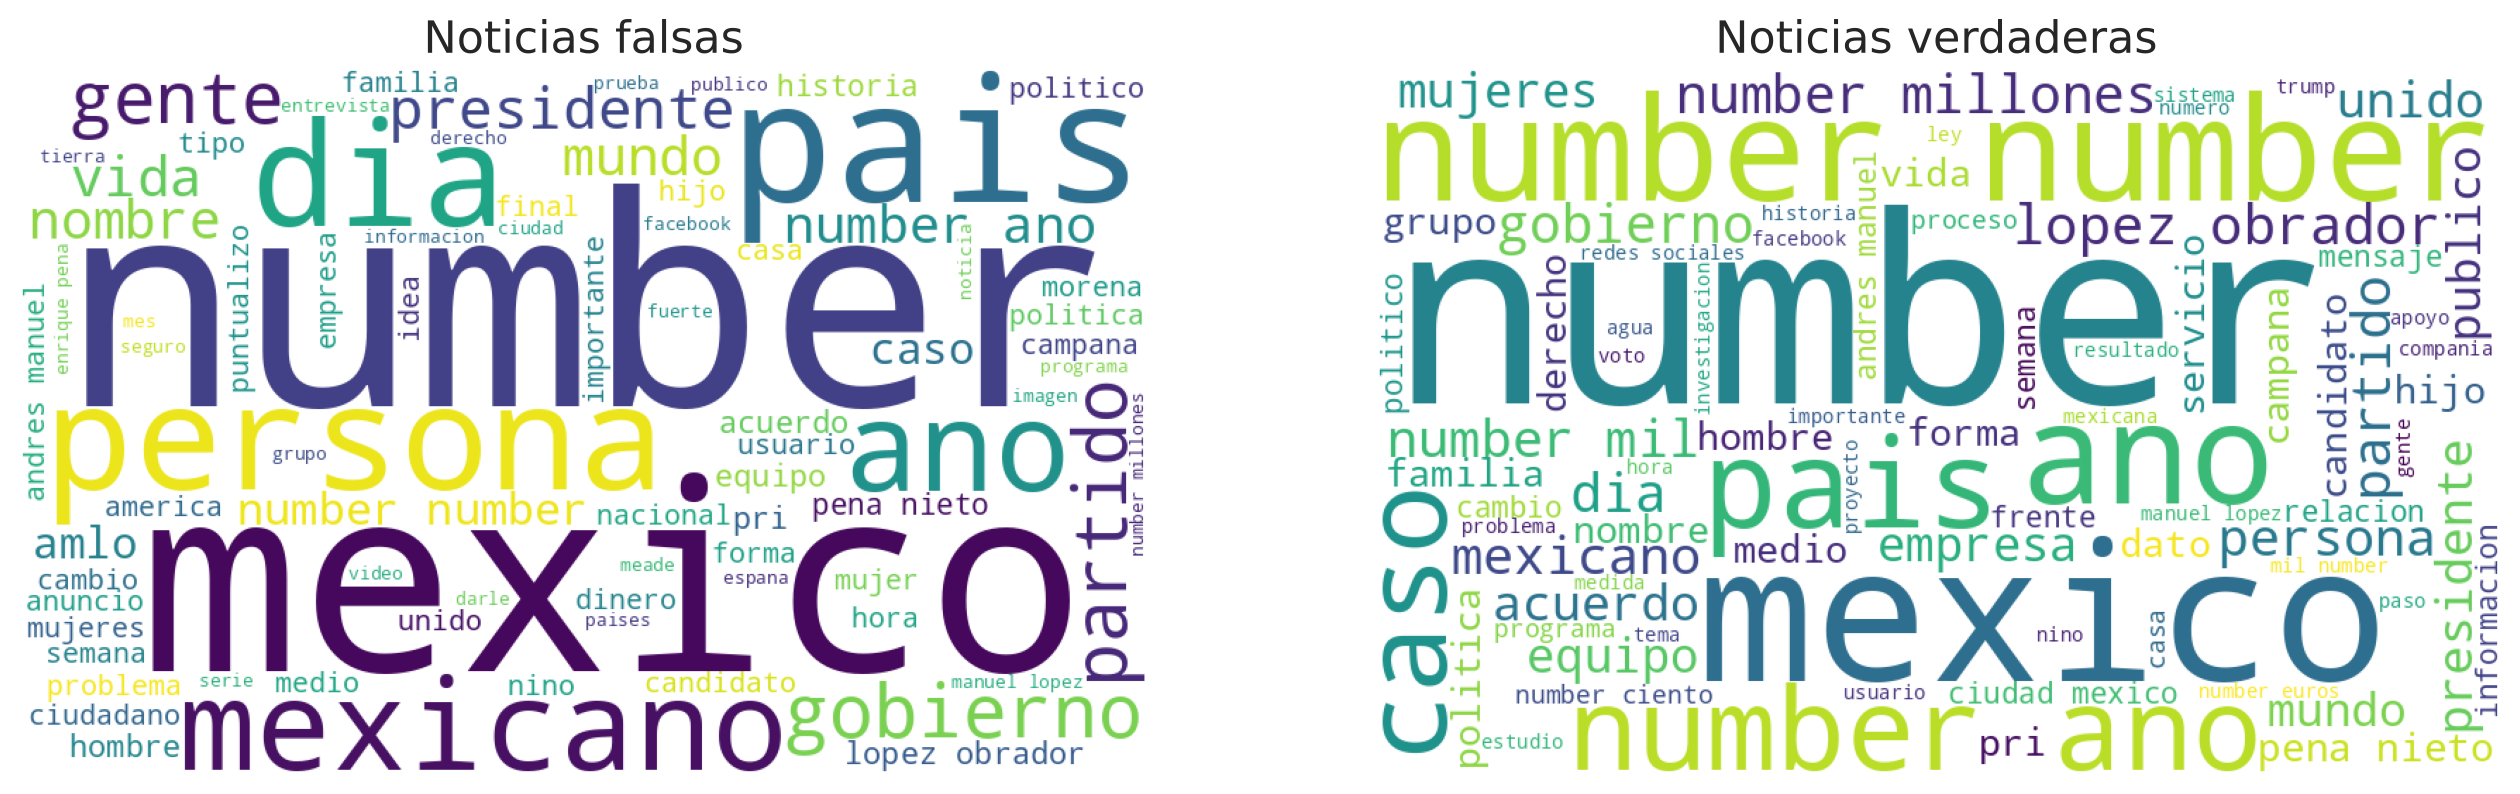

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for eje, clase, titulo in zip(ejes, [1, 0], ["Noticias falsas", "Noticias verdaderas"]):
    texto_clase = " ".join(df.loc[df["target"] == clase, "texto_prep"])
    nube = WordCloud(width=800, height=500, background_color="white", max_words=80).generate(texto_clase)
    eje.imshow(nube)
    eje.set_title(titulo, fontsize=16)
    eje.axis("off")
plt.show()

### BLOQUE D: partición del conjunto de datos en entrenamiento y validación (80/20)

Reservamos un 20 % de las noticias de 2018 para **validar** el modelo con datos que no ha visto durante el entrenamiento. Usamos `stratify` para que ambas partes mantengan la proporción de noticias falsas y verdaderas.

Partimos los **índices** de las filas (y no directamente los textos) para poder reutilizar exactamente la misma partición en el notebook 4.

In [12]:
idx_train, idx_val = train_test_split(df.index, test_size=0.2, stratify=df["target"], random_state=42)

df["particion"] = "train"
df.loc[idx_val, "particion"] = "val"
df["particion"].value_counts()

particion
train    776
val      194
Name: count, dtype: int64

In [13]:
X_train, y_train = df.loc[idx_train, "texto_prep"], df.loc[idx_train, "target"]
X_val, y_val = df.loc[idx_val, "texto_prep"], df.loc[idx_val, "target"]

### BLOQUE E: vectorización del texto con TF-IDF

Los modelos solo entienden números. **TF-IDF** (*Term Frequency - Inverse Document Frequency*) convierte cada noticia en un vector donde cada posición corresponde a una palabra del vocabulario. El peso de cada palabra es mayor cuanto más aparece en esa noticia y menor cuanto más común es en el resto de noticias.

Usaremos también **bigramas** (parejas de palabras consecutivas, como *"ultima hora"*).

In [14]:
vectorizador = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)

X_train_vec = vectorizador.fit_transform(X_train)
X_val_vec = vectorizador.transform(X_val)

print(X_train_vec.shape, X_val_vec.shape)

(776, 5000) (194, 5000)


**¿Por qué usamos `fit_transform` en entrenamiento y solo `transform` en validación?**

El vocabulario y los pesos IDF deben aprenderse **solo** con los datos de entrenamiento. Si los aprendiéramos también con los de validación, estaríamos dejando que el modelo "espiara" información que en la realidad no tendría.

In [15]:
# Algunas palabras del vocabulario aprendido
vocabulario = vectorizador.get_feature_names_out()
print(vocabulario[1000:1030])

['conozco' 'conquistar' 'consciente' 'conscientes' 'consecuencia'
 'consecuencias' 'consecutiva' 'conseguido' 'consejero'
 'consejero presidente' 'consejeros' 'consejo' 'consejos' 'consentimiento'
 'conservador' 'consideracion' 'considerada' 'considerado' 'considerados'
 'consideran' 'considerar' 'consideraron' 'consiguio' 'consiste'
 'consolidar' 'consorcio' 'consta' 'constante' 'constantes' 'constitucion']


### BLOQUE F: entrenamiento del modelo base (regresión logística)

La regresión logística estima la probabilidad de que una noticia sea falsa a partir de una combinación lineal de sus variables (aquí, los pesos TF-IDF de cada palabra). Es sencilla, rápida e interpretable: un clásico difícil de batir con pocos datos.

Más información sobre este modelo [aquí](https://cienciadedatos.net/documentos/py17-regresion-logistica-python.html).

In [16]:
modelo_lr = LogisticRegression(max_iter=1000, C=10)
modelo_lr.fit(X_train_vec, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [17]:
# Resultados sobre el conjunto de validación
pred_val = modelo_lr.predict(X_val_vec)

print(f"Accuracy: {accuracy_score(y_val, pred_val):.2f}\n")
print(classification_report(y_val, pred_val, target_names=["verdadera", "falsa"]))

Accuracy: 0.74

              precision    recall  f1-score   support

   verdadera       0.74      0.74      0.74        98
       falsa       0.74      0.73      0.73        96

    accuracy                           0.74       194
   macro avg       0.74      0.74      0.74       194
weighted avg       0.74      0.74      0.74       194



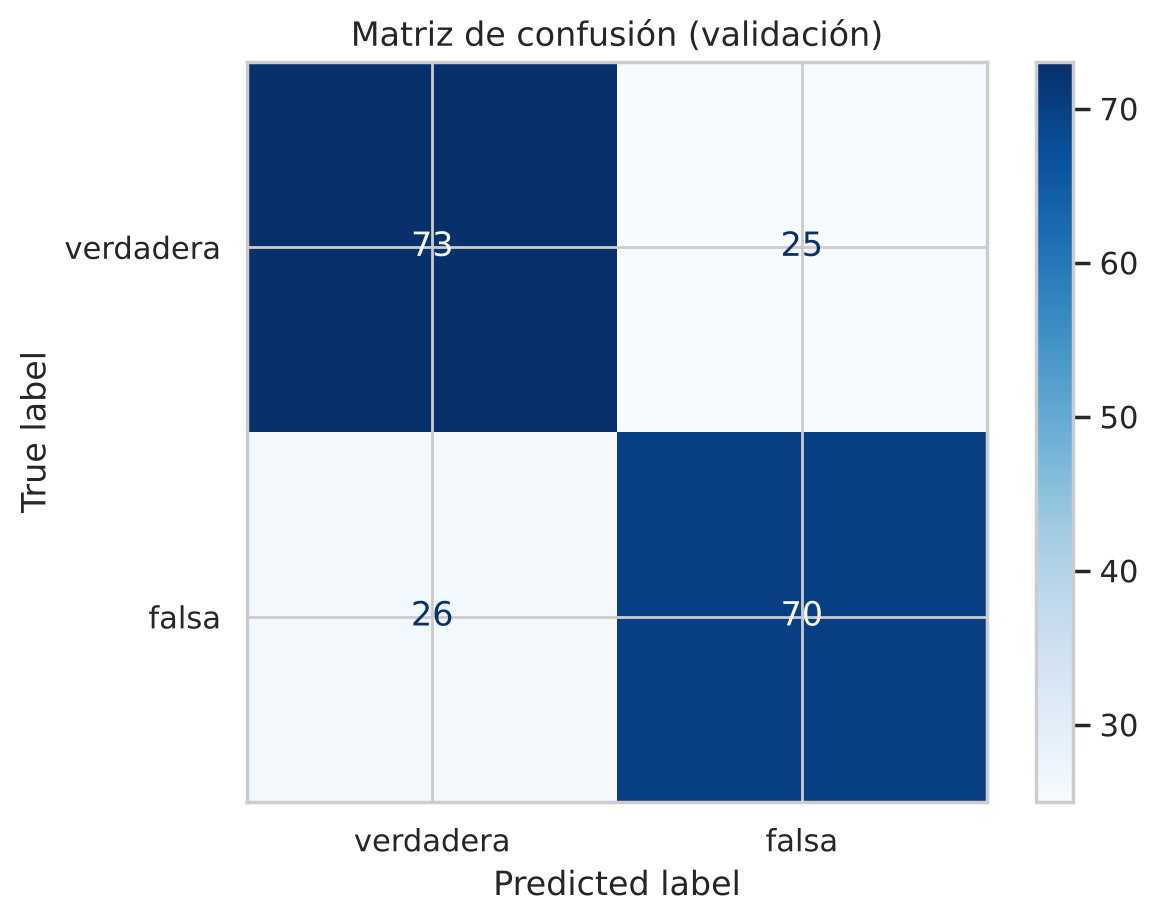

In [18]:
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["verdadera", "falsa"], cmap="Blues")
plt.title("Matriz de confusión (validación)")
plt.show()

Una ventaja de la regresión logística es que podemos ver **qué palabras empujan hacia cada clase** mirando sus coeficientes.

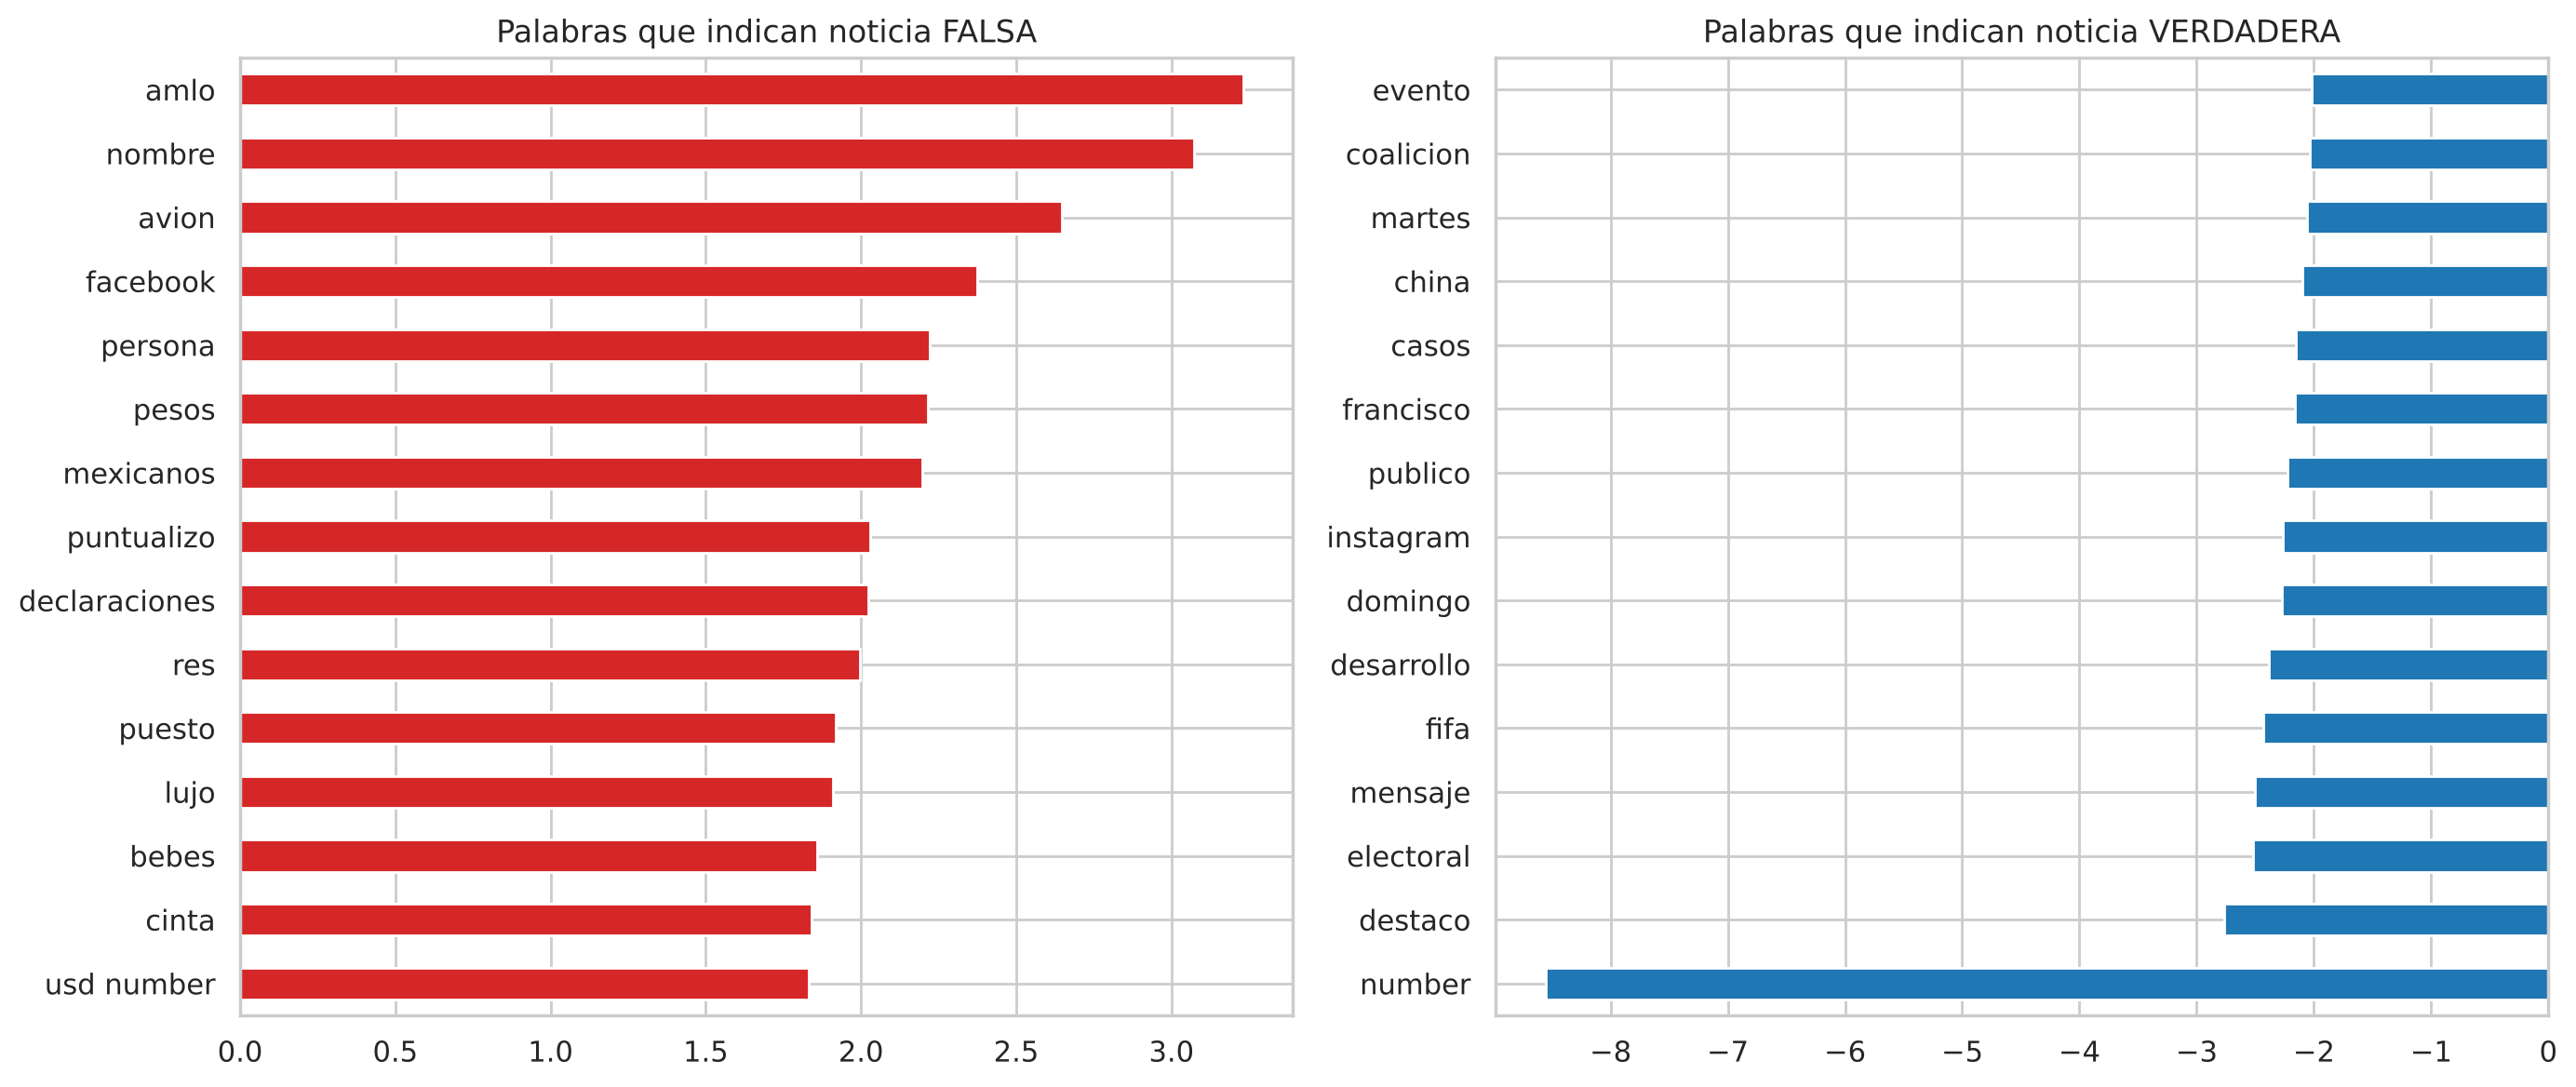

In [19]:
coeficientes = pd.Series(modelo_lr.coef_[0], index=vocabulario).sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
coeficientes.tail(15).plot(kind="barh", ax=ejes[0], color="tab:red", title="Palabras que indican noticia FALSA")
coeficientes.head(15).plot(kind="barh", ax=ejes[1], color="tab:blue", title="Palabras que indican noticia VERDADERA")
plt.tight_layout()
plt.show()

### BLOQUE G: evaluación sobre las noticias nuevas (2020-21)

Llega la prueba de fuego: noticias publicadas **dos o tres años después** y sobre temas que el modelo nunca ha visto.

In [20]:
X_nuevas_vec = vectorizador.transform(df_nuevas["texto_prep"])
pred_nuevas = modelo_lr.predict(X_nuevas_vec)

print(f"Accuracy: {accuracy_score(df_nuevas['target'], pred_nuevas):.2f}\n")
print(classification_report(df_nuevas["target"], pred_nuevas, target_names=["verdadera", "falsa"]))

Accuracy: 0.63

              precision    recall  f1-score   support

   verdadera       0.59      0.88      0.70       286
       falsa       0.76      0.38      0.50       286

    accuracy                           0.63       572
   macro avg       0.67      0.63      0.60       572
weighted avg       0.67      0.63      0.60       572



In [21]:
# ¿Conoce el modelo la palabra "covid"?
for palabra in ["covid", "vacuna", "pandemia", "mascarilla", "gobierno"]:
    print(f"{palabra:<12} {'sí' if palabra in vectorizador.vocabulary_ else 'no'}")

covid        no
vacuna       no
pandemia     no
mascarilla   no
gobierno     sí


El rendimiento cae claramente. Un modelo basado en palabras solo conoce el vocabulario que vio al entrenar: *"covid"*, *"pandemia"* o *"mascarilla"* son invisibles para él, aunque aparezcan en casi la mitad de las noticias nuevas.

Este problema se conoce como **cambio de dominio** (*domain shift*), y es justo donde el **transfer learning** puede ayudarnos: un modelo preentrenado con millones de textos ya "sabe español" antes de ver nuestros datos. Lo comprobaremos en el notebook 4.

### BLOQUE H: exportación

Guardamos la partición para reutilizarla en el notebook 4 y el modelo base (vectorizador + regresión logística) en un único `Pipeline`.

In [22]:
df[["Id", "Topic", "texto", "longitud", "target", "particion"]].to_csv(f"{DATA}/noticias_2018_particion.csv", index=False)

baseline = Pipeline([("tfidf", vectorizador), ("modelo", modelo_lr)])
joblib.dump(baseline, f"{MODELS}/baseline_tfidf_lr.joblib")

['../models/baseline_tfidf_lr.joblib']